NLP Libraries Imported Successfully!
NLP PIPELINE EXECUTION

Record ID: R001
Record Type: Discharge Summary

 Normalized Text :
patient id: pt10234. admitted: 12-03-2025.
        discharged: 18-03-2025. diagnosis: fractures of left arm.
        prescribed: paracetamol 500 mg twice daily.
        blood pressure: 120/80 mmhg. temperature: 37.2 c. age: 45 years.

 Tokens :
['patient', 'id', ':', 'pt', '10234', '.', 'admitted', ':', '12', '-', '03', '-', '2025', '.', 'discharged', ':', '18', '-', '03', '-', '2025', '.', 'diagnosis', ':', 'fractures', 'of', 'left', 'arm', '.', 'prescribed', ':', 'paracetamol', '500 mg', 'twice', 'daily', '.', 'blood', 'pressure', ':', '120', '/', '80 mmhg', '.', 'temperature', ':', '37.2', 'c', '.', 'age', ':', '45', 'years', '.']

 Entities :
{'Patient ID': ['PT10234'], 'Admission Date': ['12/03/2025', '18/03/2025'], 'Discharge Date': ['12/03/2025', '18/03/2025'], 'Drug Strength': ['Paracetamol 500 mg'], 'Dosage Frequency': ['twice', 'daily'], 'Blood Press

,Test Case,Input,Expected,Actual,Status
0,Patient ID,PT12345,True,True,PASS
1,Invalid Patient ID,PT12AB,False,False,PASS
2,Blood Pressure,120/80 mmHg,True,True,PASS
3,Invalid BP,120-80 mmHg,False,False,PASS
4,Temperature,37.2 C,True,True,PASS
5,Invalid Temperature,Hot,False,False,PASS
6,ICD Code,A12.3,True,True,PASS
7,Invalid ICD Code,12345,False,False,PASS
8,Morphology,fractures,True,True,PASS
9,Unknown Word,unknownword,False,False,PASS


Total Tests: 10
Passed: 10
Failed: 0

PERFORMANCE EVALUATION


,Record ID,Record Type,Tokens Processed,Entities Found,Morphological Analyses,Runtime (Seconds)
0,R001,Discharge Summary,53,11,2,0.000844
1,R002,Prescription,30,4,1,0.001017
2,R003,Operation Note,27,3,2,0.000339
3,R004,Nursing Observation,32,4,1,0.000330



PERFORMANCE SUMMARY
Total Records: 4
Total Tokens: 142
Total Entities: 22
Total Morphological Analyses: 6
Total Runtime: 0.002530228999830797


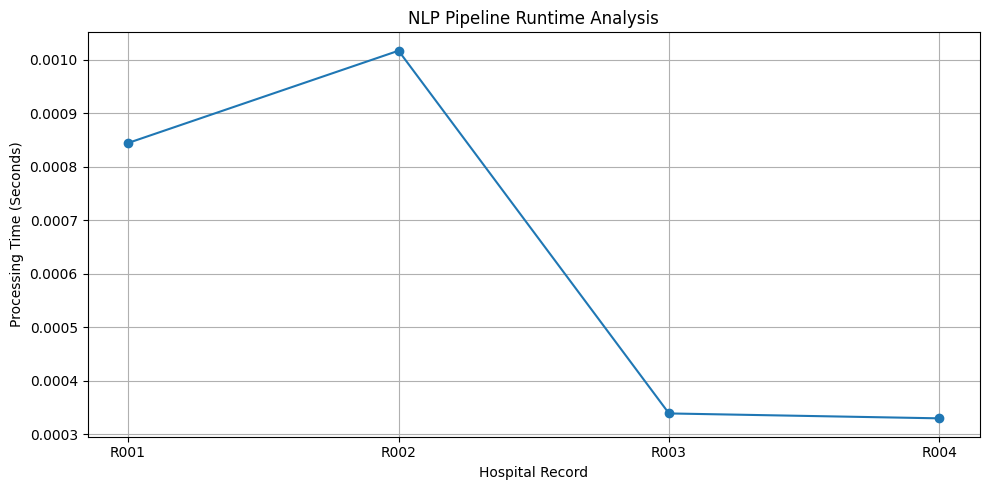


Results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
!pip install nltk -q

import re
import nltk
import time
import pandas as pd
import matplotlib.pyplot as plt

from collections import defaultdict
from nltk.stem import PorterStemmer
from IPython.display import display

print("NLP Libraries Imported Successfully!")


# ============================================================
# 1. SAMPLE HOSPITAL DATASET
# ============================================================

records = [
    {
        "id": "R001",
        "type": "Discharge Summary",
        "text": """Patient ID: PT10234. Admitted: 12/03/2025.
        Discharged: 18/03/2025. Diagnosis: fractures of left arm.
        Prescribed: Paracetamol 500 mg twice daily.
        BP: 120/80 mmHg. Temperature: 37.2 C. Age: 45 years."""
    },
    {
        "id": "R002",
        "type": "Prescription",
        "text": """Patient ID: PT20456. Drug: Amoxicillin 250mg.
        Dosage: 1 tablet three times daily.
        Duration: 5 days. Patient reported fever and coughing."""
    },
    {
        "id": "R003",
        "type": "Operation Note",
        "text": """Patient ID: PT30987. Procedure: nephrectomy.
        Patient monitored after surgery.
        BP: 130/85 mmHg. Temperature: 36.8 C."""
    },
    {
        "id": "R004",
        "type": "Nursing Observation",
        "text": """Patient ID: PT40567. Patient recovering.
        Pulse: 82 bpm. Temperature: 37 C.
        Blood pressure: 118/76 mmHg.
        Complaints of pain for 2 days."""
    }
]


# ============================================================
# 2. REGULAR EXPRESSION TOKENIZER
# ============================================================

token_pattern = re.compile(
    r'\d+(?:\.\d+)?(?:\s?(?:mg|mcg|g|kg|ml|mmHg|bpm))?'
    r'|[A-Za-z]+(?:[.-][A-Za-z]+)*'
    r'|[^\w\s]',
    re.IGNORECASE
)


def tokenize(text):
    return token_pattern.findall(text)


# ============================================================
# 3. CLINICAL ENTITY RECOGNITION - 12 PATTERNS
# ============================================================

patterns = {

    "Patient ID":
        r'\bPT\d{5}\b',

    "Admission Date":
        r'\b\d{2}[/-]\d{2}[/-]\d{4}\b',

    "Discharge Date":
        r'\b\d{2}[/-]\d{2}[/-]\d{4}\b',

    "Drug Strength":
        r'\b[A-Za-z][A-Za-z-]*\s*\d+(?:\.\d+)?\s?(?:mg|mcg|g|ml)\b',

    "Dosage Frequency":
        r'\b(?:once|twice|thrice|\d+\s?times?\s?daily|daily|weekly)\b',

    "Laboratory Value":
        r'\b(?:Hb|WBC|RBC|glucose|creatinine)\s*:?\s*\d+(?:\.\d+)?\s?(?:mg/dL|g/dL|mmol/L|%)\b',

    "Blood Pressure":
        r'\b(?:BP\s*:?\s*)?\d{2,3}/\d{2,3}\s?mmHg\b',

    "Temperature":
        r'\b(?:Temperature\s*:?\s*)?\d{2}(?:\.\d+)?\s?°?\s?(?:C|F)\b',

    "ICD Code":
        r'\b[A-TV-Z]\d{2}(?:\.\d{1,4})?\b',

    "Ward and Bed":
        r'\bWard\s*[A-Z0-9-]+\s*,?\s*Bed\s*\d+\b',

    "Contact Number":
        r'\b(?:\+?\d{1,3}[- ]?)?\d{10}\b',

    "Age":
        r'\bAge\s*:?\s*\d{1,3}\s*(?:years?|yrs?)\b',

    "Symptom Duration":
        r'\b(?:for\s+)?\d+\s*(?:hours?|days?|weeks?|months?)\b'
}


def extract_entities(text):

    result = {}

    for name, pattern in patterns.items():

        matches = re.findall(
            pattern,
            text,
            re.IGNORECASE
        )

        if matches:
            result[name] = matches

    return result


# ============================================================
# 4. TEXT NORMALISATION
# ============================================================

def normalize_text(text):

    text = text.lower()

    abbreviations = {
        "bp": "blood pressure",
        "temp": "temperature",
        "bid": "twice daily",
        "tid": "three times daily",
        "qd": "once daily",
        "htn": "hypertension",
        "dm": "diabetes mellitus",
        "hr": "heart rate",
        "iv": "intravenous",
        "im": "intramuscular"
    }

    for short, full in abbreviations.items():

        text = re.sub(
            r'\b' + short + r'\b',
            full,
            text,
            flags=re.IGNORECASE
        )

    text = re.sub(
        r'(\d{2})/(\d{2})/(\d{4})',
        r'\1-\2-\3',
        text
    )

    return text


# ============================================================
# 5. DETERMINISTIC FINITE AUTOMATON (DFA)
# ============================================================

class DFA:

    def __init__(self, states, alphabet,
                 transitions, start, final):

        self.states = states
        self.alphabet = alphabet
        self.transitions = transitions
        self.start = start
        self.final = final

    def accepts(self, string):

        state = self.start

        for symbol in string:

            if (state, symbol) not in self.transitions:
                return False

            state = self.transitions[(state, symbol)]

        return state in self.final


digit_dfa = DFA(
    states={0, 1, 2},
    alphabet={"D"},
    transitions={
        (0, "D"): 1,
        (1, "D"): 2
    },
    start=0,
    final={2}
)


def convert_digits(text):

    return ''.join(
        'D' if char.isdigit() else char
        for char in text
    )


# ============================================================
# 6. NON-DETERMINISTIC FINITE AUTOMATON (NFA)
# ============================================================

class NFA:

    def __init__(self, transitions, start,
                 final, alphabet):

        self.transitions = transitions
        self.start = start
        self.final = final
        self.alphabet = alphabet

    def epsilon_closure(self, states):

        closure = set(states)
        stack = list(states)

        while stack:

            state = stack.pop()

            for next_state in self.transitions.get(
                (state, None), set()
            ):

                if next_state not in closure:

                    closure.add(next_state)
                    stack.append(next_state)

        return frozenset(closure)

    def move(self, states, symbol):

        result = set()

        for state in states:

            result.update(
                self.transitions.get(
                    (state, symbol), set()
                )
            )

        return result

    def subset_construction(self):

        start = self.epsilon_closure({self.start})

        queue = [start]
        visited = {start}

        dfa_transitions = {}
        dfa_final = set()

        while queue:

            current = queue.pop(0)

            if current & self.final:
                dfa_final.add(current)

            for symbol in self.alphabet:

                target = self.epsilon_closure(
                    self.move(current, symbol)
                )

                if target:

                    dfa_transitions[
                        (current, symbol)
                    ] = target

                    if target not in visited:

                        visited.add(target)
                        queue.append(target)

        return (
            dfa_transitions,
            start,
            dfa_final,
            visited
        )


# NFA construction

transitions = defaultdict(set)

transitions[(0, None)].update({1, 5})

# Branch 1: PT followed by two digits

transitions[(1, "P")].add(2)
transitions[(2, "T")].add(3)
transitions[(3, "D")].add(4)
transitions[(4, "D")].add(7)

# Branch 2: two digits

transitions[(5, "D")].add(6)
transitions[(6, "D")].add(7)


nfa = NFA(
    transitions=transitions,
    start=0,
    final={7},
    alphabet={"P", "T", "D"}
)


dfa_transitions, dfa_start, dfa_final, dfa_states = (
    nfa.subset_construction()
)


# ============================================================
# 7. FINITE STATE MORPHOLOGICAL TRANSDUCER
# ============================================================

class MorphologicalTransducer:

    def __init__(self):

        self.lexicon = {

            "fracture": ("fracture", "+N", "+SG"),
            "fractures": ("fracture", "+N", "+PL"),

            "fractured": ("fracture", "+V", "+PAST"),
            "fracturing": ("fracture", "+V", "+PROG"),

            "patient": ("patient", "+N", "+SG"),
            "patients": ("patient", "+N", "+PL"),

            "treated": ("treat", "+V", "+PAST"),
            "treating": ("treat", "+V", "+PROG"),

            "nephrectomy": ("nephrectomy", "+N", "+SG"),
            "nephrectomies": ("nephrectomy", "+N", "+PL"),

            "cough": ("cough", "+N", "+SG"),
            "coughs": ("cough", "+N", "+PL")
        }

        self.generation = {

            value: key
            for key, value in self.lexicon.items()

        }

    def parse(self, word):

        word = word.lower()

        if word == "treated":

            return [
                ("treat", "+V", "+PAST"),
                ("treat", "+ADJ", "+PART")
            ]

        if word in self.lexicon:

            return self.lexicon[word]

        return None

    def generate(self, lemma, features):

        key = (lemma,) + tuple(features)

        return self.generation.get(key)


fst = MorphologicalTransducer()


# ============================================================
# 8. PORTER STEMMER
# ============================================================

stemmer = PorterStemmer()


def porter_stem(word):

    return stemmer.stem(word.lower())


# ============================================================
# 9. COMPLETE NLP PIPELINE
# ============================================================

def nlp_pipeline(text):

    # Text normalisation

    normalized = normalize_text(text)

    # Tokenisation

    tokens = tokenize(normalized)

    # Entity recognition

    entities = extract_entities(text)

    # Morphological analysis

    morphology = {}

    for word in tokens:

        if word.isalpha():

            result = fst.parse(word)

            if result:
                morphology[word] = result

    # Porter stemming

    stems = []

    for word in tokens:

        if word.isalpha():

            stems.append(
                porter_stem(word)
            )

    return {

        "Normalized Text": normalized,

        "Tokens": tokens,

        "Entities": entities,

        "Morphology": morphology,

        "Stems": stems
    }


# ============================================================
# 10. RUN COMPLETE PIPELINE ON ALL RECORDS
# ============================================================

print("=" * 65)
print("NLP PIPELINE EXECUTION")
print("=" * 65)

for record in records:

    print("\nRecord ID:", record["id"])
    print("Record Type:", record["type"])

    output = nlp_pipeline(record["text"])

    for stage, result in output.items():

        print("\n", stage, ":")

        print(result)

    print("-" * 65)


# ============================================================
# 11. DFA TESTING
# ============================================================

print("\nDFA TESTING")

print(
    "42 Accepted:",
    digit_dfa.accepts(convert_digits("42"))
)

print(
    "123 Accepted:",
    digit_dfa.accepts(convert_digits("123"))
)

print(
    "5 Accepted:",
    digit_dfa.accepts(convert_digits("5"))
)


# ============================================================
# 12. NFA TO DFA SUBSET CONSTRUCTION
# ============================================================

print("\nNFA TO DFA SUBSET CONSTRUCTION")

print("DFA States:")

for state in sorted(
    dfa_states,
    key=lambda x: tuple(sorted(x))
):

    print(sorted(state))


print("\nDFA Final States:")

for state in dfa_final:

    print(sorted(state))


print("\nDFA TRANSITION TABLE")

for (state, symbol), target in dfa_transitions.items():

    print(
        sorted(state),
        "--", symbol, "-->",
        sorted(target)
    )


# ============================================================
# 13. MORPHOLOGICAL PARSING AND GENERATION
# ============================================================

print("\nMORPHOLOGICAL PARSING")

clinical_words = [

    "fractures",
    "fractured",
    "fracturing",
    "patients",
    "nephrectomies",
    "treated"
]

for word in clinical_words:

    print(
        word,
        "->",
        fst.parse(word)
    )


print("\nMORPHOLOGICAL GENERATION")

print(
    "fracture +N +PL ->",
    fst.generate("fracture", ["+N", "+PL"])
)


# ============================================================
# 14. PORTER STEMMER TESTING
# ============================================================

print("\nPORTER STEMMER RESULTS")

words = [

    "fractures",
    "fractured",
    "fracturing",
    "patients",
    "coughing",
    "nephrectomies",
    "treated",
    "monitoring"
]

for word in words:

    print(
        word,
        "->",
        porter_stem(word)
    )


# ============================================================
# 15. TEST CASES AND VALIDATION
# ============================================================

test_cases = [

    (
        "Patient ID",
        "PT12345",
        True,
        lambda x: bool(
            re.fullmatch(patterns["Patient ID"], x)
        )
    ),

    (
        "Invalid Patient ID",
        "PT12AB",
        False,
        lambda x: bool(
            re.fullmatch(patterns["Patient ID"], x)
        )
    ),

    (
        "Blood Pressure",
        "120/80 mmHg",
        True,
        lambda x: bool(
            re.search(patterns["Blood Pressure"], x)
        )
    ),

    (
        "Invalid BP",
        "120-80 mmHg",
        False,
        lambda x: bool(
            re.search(patterns["Blood Pressure"], x)
        )
    ),

    (
        "Temperature",
        "37.2 C",
        True,
        lambda x: bool(
            re.search(patterns["Temperature"], x)
        )
    ),

    (
        "Invalid Temperature",
        "Hot",
        False,
        lambda x: bool(
            re.search(patterns["Temperature"], x)
        )
    ),

    (
        "ICD Code",
        "A12.3",
        True,
        lambda x: bool(
            re.fullmatch(patterns["ICD Code"], x)
        )
    ),

    (
        "Invalid ICD Code",
        "12345",
        False,
        lambda x: bool(
            re.fullmatch(patterns["ICD Code"], x)
        )
    ),

    (
        "Morphology",
        "fractures",
        True,
        lambda x: fst.parse(x) is not None
    ),

    (
        "Unknown Word",
        "unknownword",
        False,
        lambda x: fst.parse(x) is not None
    )
]


test_results = []

for name, value, expected, function in test_cases:

    actual = function(value)

    status = (
        "PASS"
        if actual == expected
        else "FAIL"
    )

    test_results.append({

        "Test Case": name,

        "Input": value,

        "Expected": expected,

        "Actual": actual,

        "Status": status
    })


test_df = pd.DataFrame(test_results)

print("\nTEST CASE RESULTS")

display(test_df)

print("Total Tests:", len(test_df))

print(
    "Passed:",
    (test_df["Status"] == "PASS").sum()
)

print(
    "Failed:",
    (test_df["Status"] == "FAIL").sum()
)


# ============================================================
# 16. PERFORMANCE EVALUATION
# ============================================================

performance = []

for record in records:

    start_time = time.perf_counter()

    result = nlp_pipeline(record["text"])

    end_time = time.perf_counter()

    runtime = end_time - start_time

    entity_count = sum(
        len(values)
        for values in result["Entities"].values()
    )

    performance.append({

        "Record ID": record["id"],

        "Record Type": record["type"],

        "Tokens Processed": len(result["Tokens"]),

        "Entities Found": entity_count,

        "Morphological Analyses": len(
            result["Morphology"]
        ),

        "Runtime (Seconds)": runtime
    })


performance_df = pd.DataFrame(performance)

print("\nPERFORMANCE EVALUATION")

display(performance_df)


# ============================================================
# 17. PERFORMANCE SUMMARY
# ============================================================

print("\nPERFORMANCE SUMMARY")

print(
    "Total Records:",
    len(performance_df)
)

print(
    "Total Tokens:",
    performance_df["Tokens Processed"].sum()
)

print(
    "Total Entities:",
    performance_df["Entities Found"].sum()
)

print(
    "Total Morphological Analyses:",
    performance_df["Morphological Analyses"].sum()
)

print(
    "Total Runtime:",
    performance_df["Runtime (Seconds)"].sum()
)


# ============================================================
# 18. GRAPHICAL REPRESENTATION
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    performance_df["Record ID"],
    performance_df["Runtime (Seconds)"],
    marker="o"
)

plt.xlabel("Hospital Record")

plt.ylabel("Processing Time (Seconds)")

plt.title("NLP Pipeline Runtime Analysis")

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 19. SAVE RESULTS
# ============================================================

performance_df.to_csv(
    "NLP_Task10_Results.csv",
    index=False
)

test_df.to_csv(
    "NLP_Task10_Test_Results.csv",
    index=False
)

print("\nResults saved successfully!")


# ============================================================
# 20. DOWNLOAD RESULTS FROM GOOGLE COLAB
# ============================================================

from google.colab import files

files.download("NLP_Task10_Results.csv")

files.download("NLP_Task10_Test_Results.csv")


# ============================================================
# END OF TASK 10 IMPLEMENTATION
# ============================================================